# Explanatory Data Analysis

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import numpy as np

In [7]:
data = pd.read_csv('housing/housing.csv')
data.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [8]:
data_num = ['housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']
data_cat = ['ocean_proximity']

## Univariate Analysis

### Numerical

array([[<Axes: title={'center': 'housing_median_age'}>,
        <Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>],
       [<Axes: title={'center': 'population'}>,
        <Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>],
       [<Axes: title={'center': 'median_house_value'}>, <Axes: >,
        <Axes: >]], dtype=object)

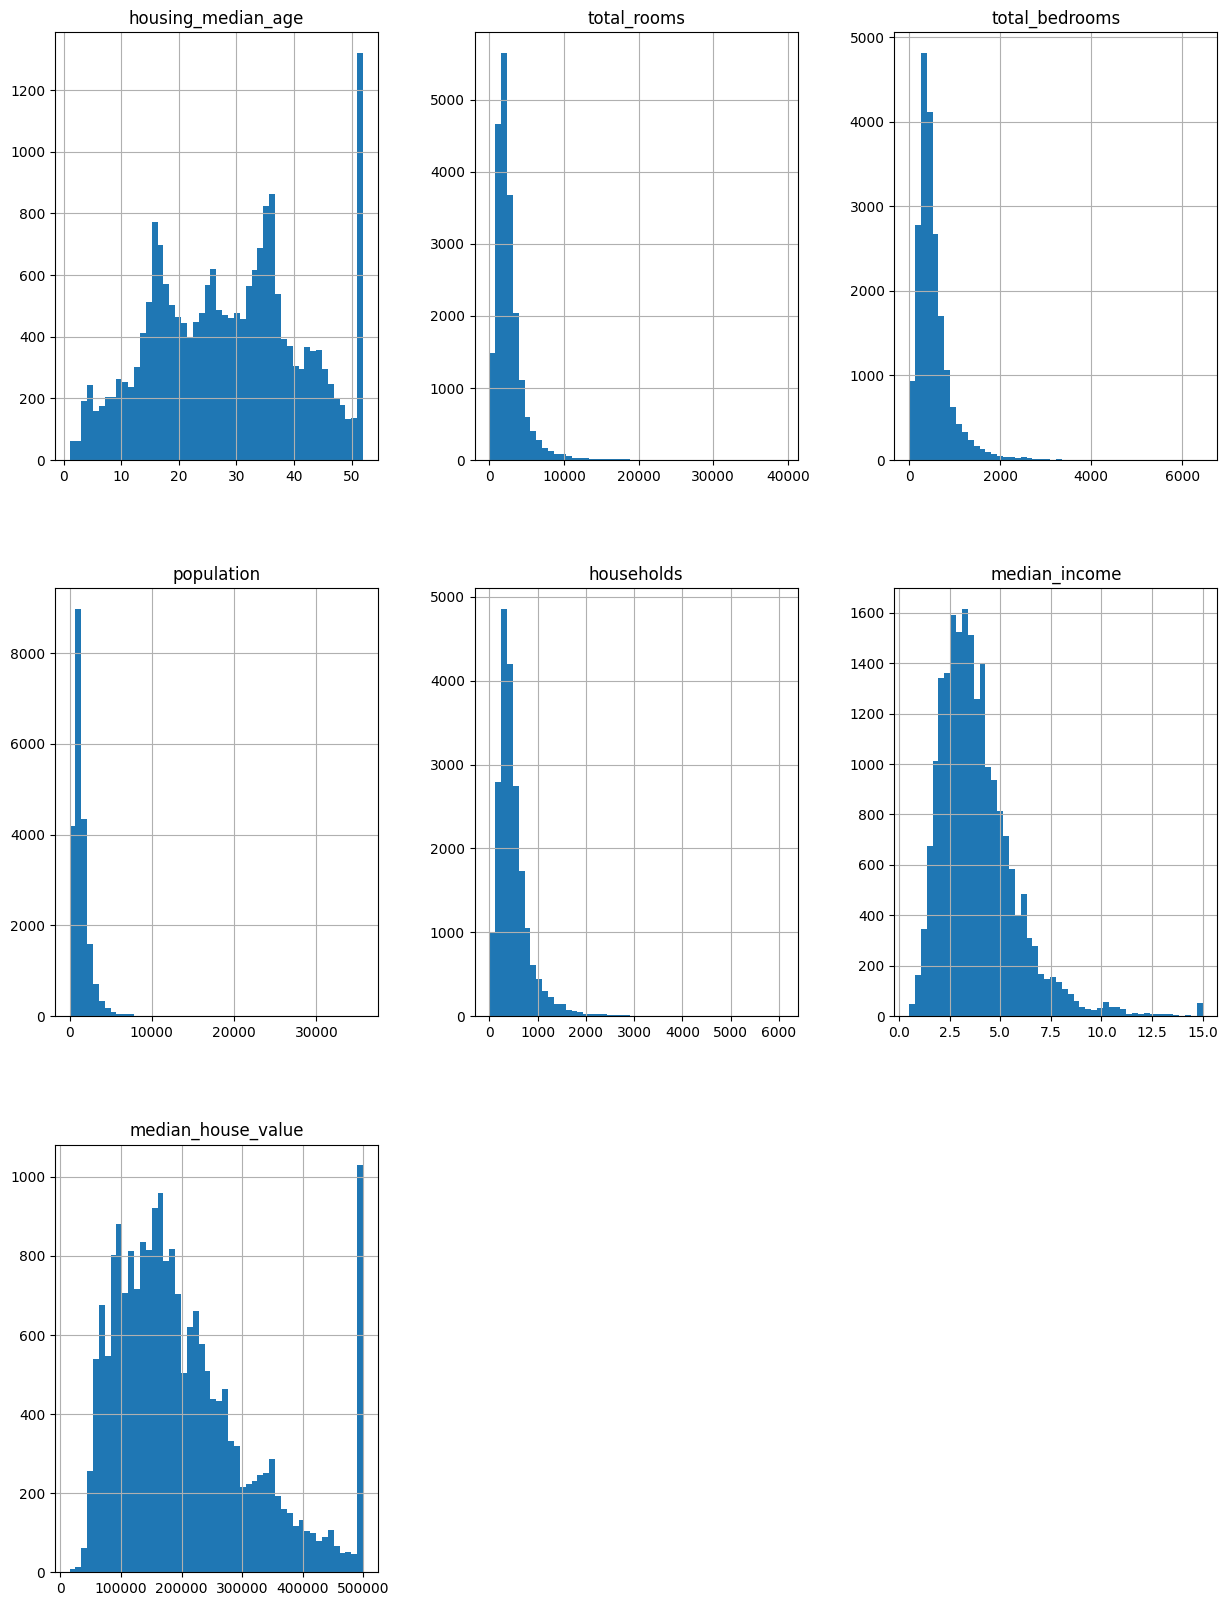

In [9]:
data[data_num].hist(bins=50, figsize=(15, 20))

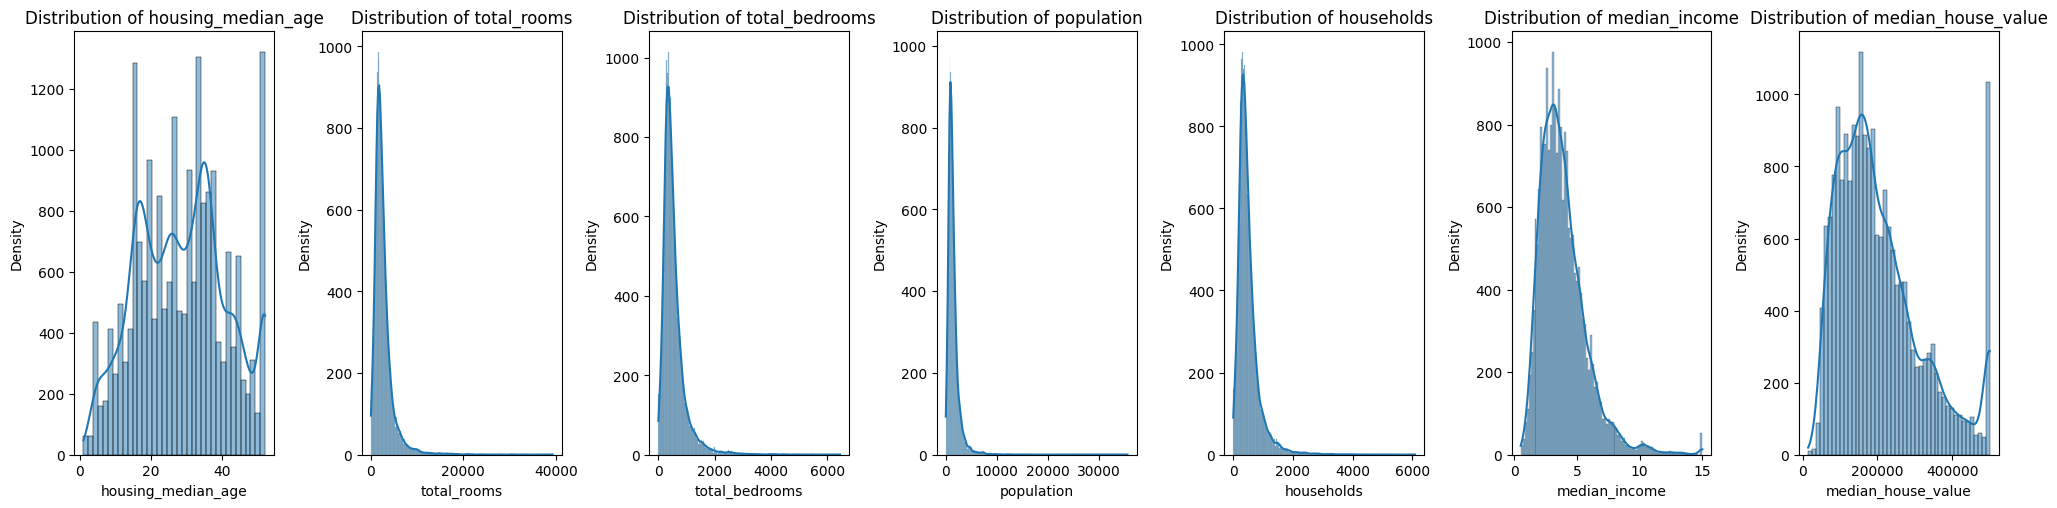

In [10]:
fig, axs = plt.subplots(ncols=len(data_num), figsize=(20, 5))

for i, column in enumerate(data_num):
    sns.histplot(data[column], kde=True, ax=axs[i])
    axs[i].set_title(f'Distribution of {column}')
    axs[i].set_xlabel(column)
    axs[i].set_ylabel('Density')

plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=1.0)
plt.show()

### Categorical

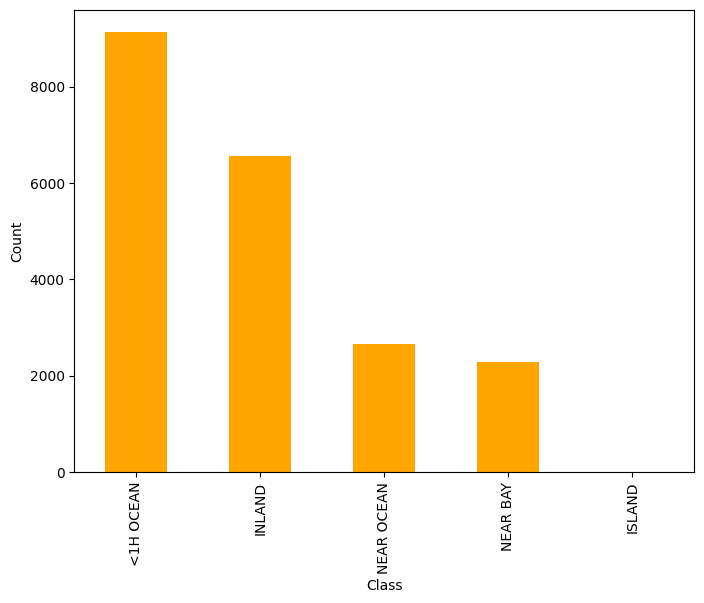

In [13]:
cat_counts = data['ocean_proximity'].value_counts()

plt.figure(figsize=(8, 6))
cat_counts.plot(kind='bar', color='orange')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

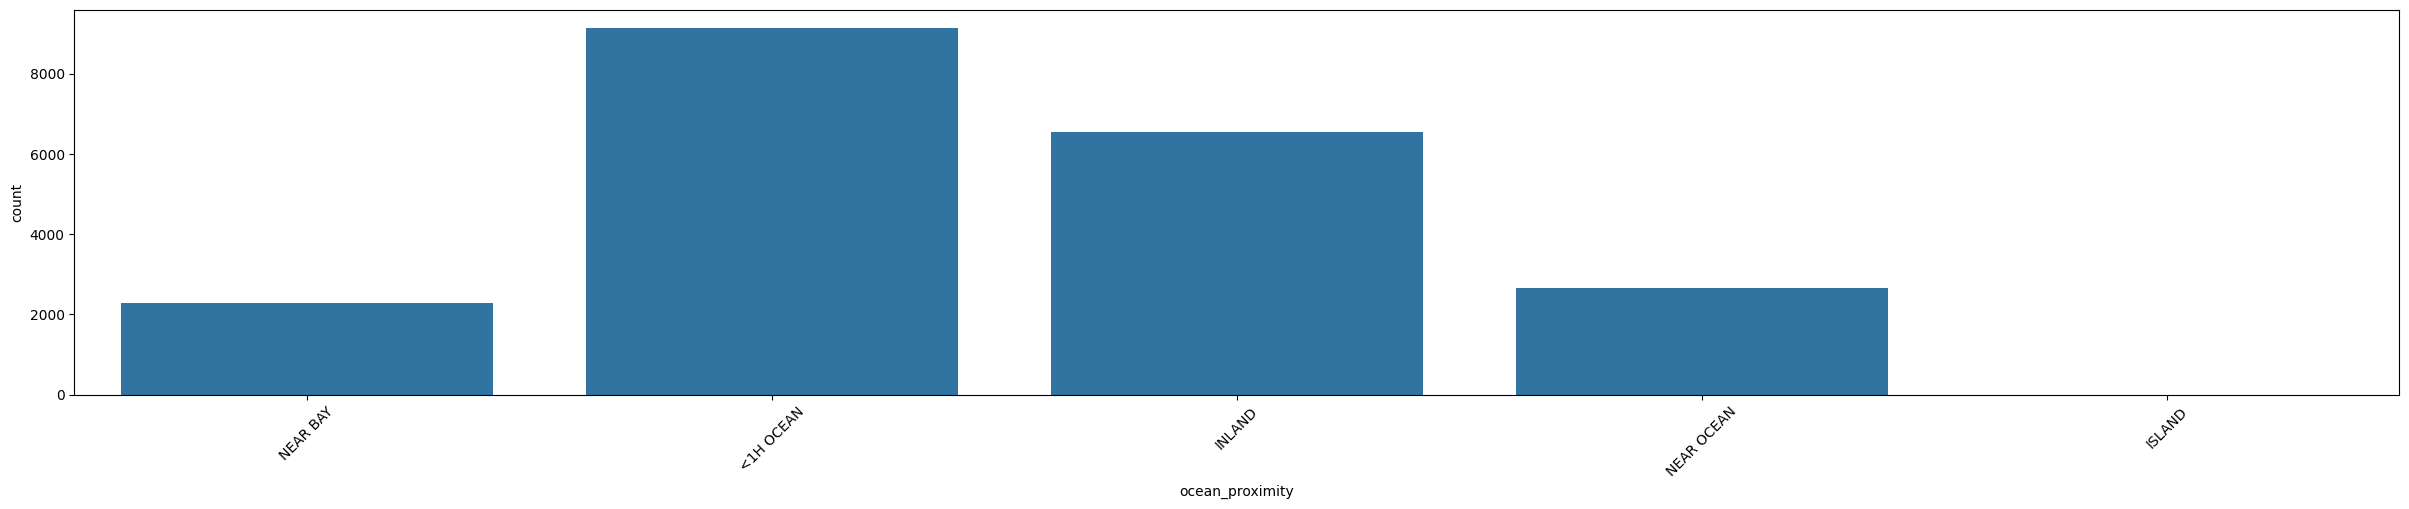

In [14]:
plt.figure(figsize=(30, 5))
sns.countplot(data=data, x='ocean_proximity')
plt.xticks(rotation=45)
plt.show

## Bivariate Analysis

### Numerical vs Numerical

<Figure size 800x600 with 0 Axes>

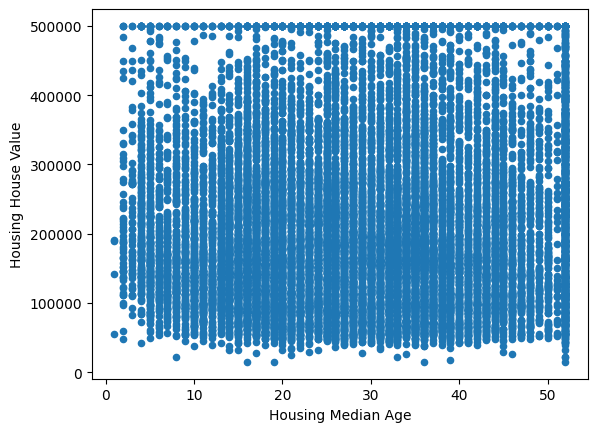

In [15]:
plt.figure(figsize=(8,6))
data.plot(kind='scatter', x='housing_median_age', y='median_house_value')
plt.xlabel('Housing Median Age')
plt.ylabel('Housing House Value')
plt.show()

(array([0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5]),
 [Text(0.5, 0, 'housing_median_age'),
  Text(1.5, 0, 'total_rooms'),
  Text(2.5, 0, 'total_bedrooms'),
  Text(3.5, 0, 'population'),
  Text(4.5, 0, 'households'),
  Text(5.5, 0, 'median_income'),
  Text(6.5, 0, 'median_house_value')])

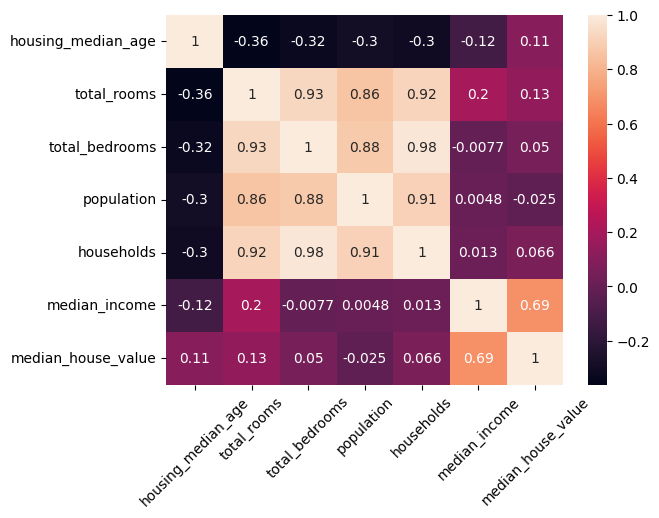

In [16]:
sns.heatmap(data[data_num].corr(), annot=True)
plt.xticks(rotation=45)

### Numerical vs Categorical

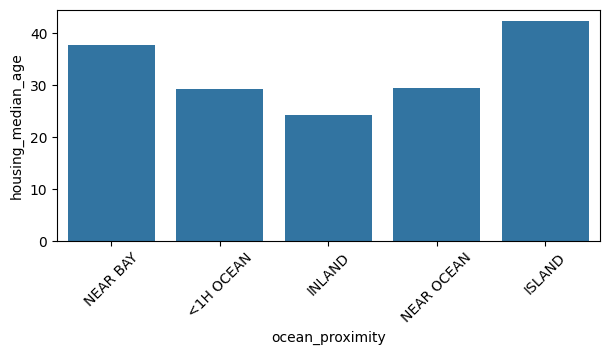

In [18]:
plt.figure(figsize=(7, 3))
sns.barplot(data=data, x='ocean_proximity', y='housing_median_age', errorbar=None)
plt.xticks(rotation=45)
plt.show()

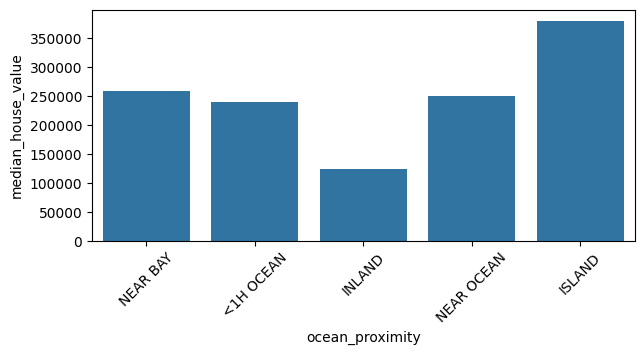

In [19]:
def plot_num_cat(x, y):
    plt.figure(figsize=(7, 3))
    sns.barplot(data=data, x=x, y=y, errorbar=None)
    plt.xticks(rotation=45)
    plt.show()

plot_num_cat('ocean_proximity', 'median_house_value')

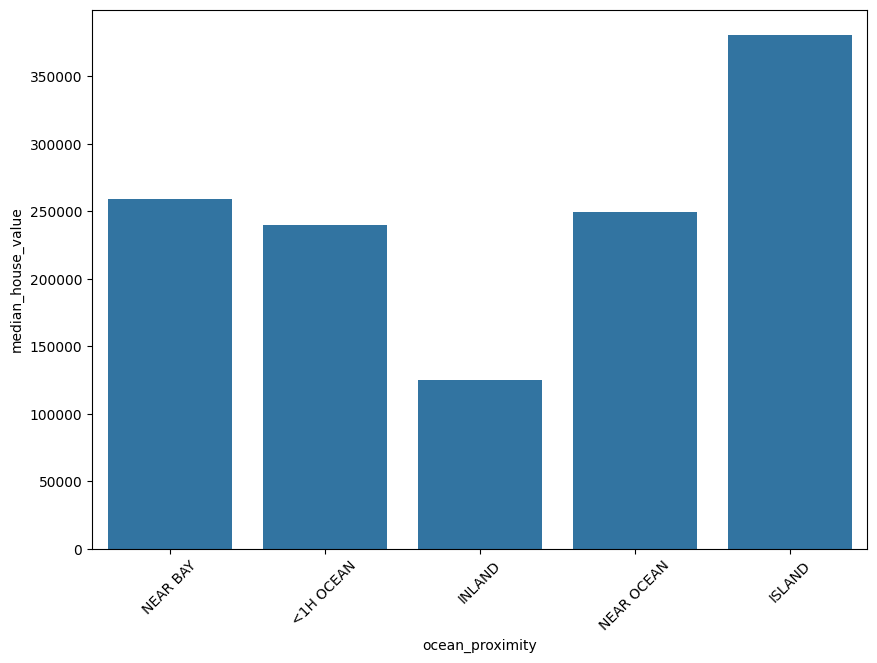

In [ ]:
def plot_num_cat(cols):
    # Kalau hanya 1 pasangan ubah menjadi list 
    if isinstance(cols, tuple):
        cols = [cols] # > [('ocean_proximity', 'median_house_value')] -> agar bisa di loop

    n = len(cols)

    if n == 1: 
        x, y = cols[0]
        plt.figure(figsize=(10, 7))
        sns.barplot(data=data, x=x, y=y, errorbar=None)
        plt.xticks(rotation=45)
        plt.show()

    else:
        # Kalau banyak pasangan
        fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(10, 3*n)) # > 3 kali jumlah plot
        
        if n == 1:
            axes = [axes] # awalnya axes = <AxesSubplot object> diubah menjadi list karena banyak plot menjadi axes = [<AxesSubplot object>]

        for i, (x, y) in enumerate(cols):
            sns.barplot(data=data, x=x, y=y, errorbar=None, ax=axes[i])
            axes[i].tick_params(axis='x', rotation=45)

        plt.tight_layout()
        plt.show()

plot_num_cat(('ocean_proximity', 'median_house_value'))

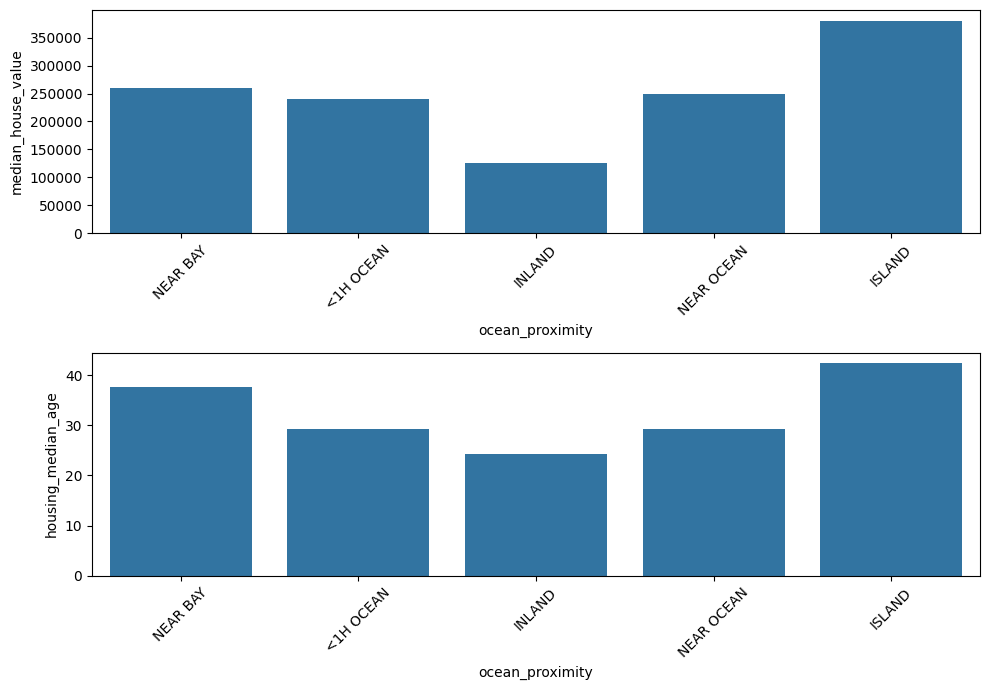

In [26]:
plot_num_cat([
    ('ocean_proximity', 'median_house_value'),
    ('ocean_proximity', 'housing_median_age')
])

### Categorical vs Categorical

In [ ]:
plt.figure(figsize=(15, 3))
sns.barplot(data=data, x='ocean_proximity', y='cat_cols', errobar=None)
plt.show()

## Multivariate Analysis

In [29]:
fig = px.scatter(data, x='housing_median_age', y='median_house_value', color='ocean_proximity')
fig.show()

## Sampling for EDA

<Axes: xlabel='housing_median_age', ylabel='median_house_value'>

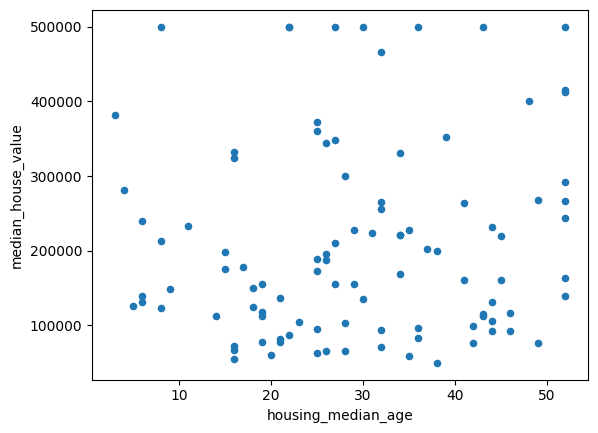

In [ ]:
### Without Replacement 

sampling_whr_num = data[['housing_median_age', 'median_house_value']].sample(n=100, replace=False)
sampling_whr_num.plot(kind='scatter', x='housing_median_age', y='median_house_value')

<Axes: xlabel='housing_median_age', ylabel='median_house_value'>

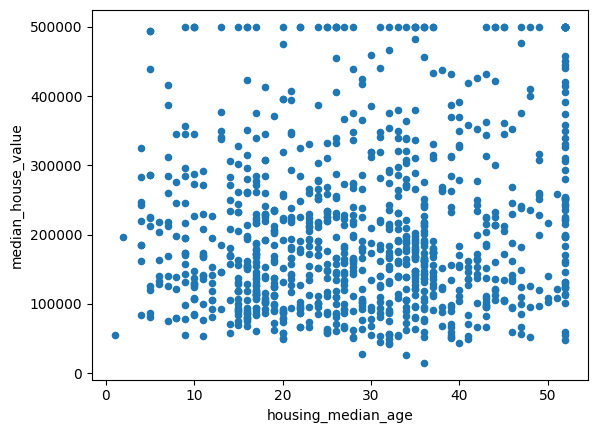

In [36]:
### With Replacement 

sam_wr_num = data[['housing_median_age', 'median_house_value']].sample(n=1000, replace=True)
sam_wr_num.plot(kind='scatter', x='housing_median_age', y='median_house_value')

## Grouping for EDA

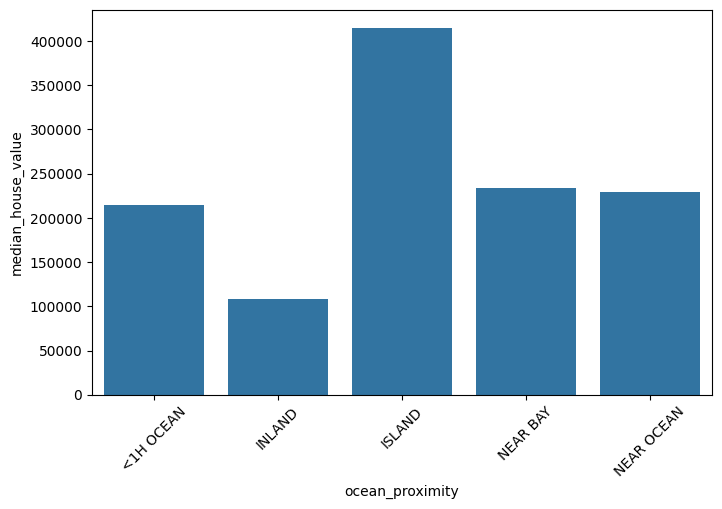

In [39]:
grouped_data = data.groupby('ocean_proximity')['median_house_value'].median().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=grouped_data, x='ocean_proximity', y='median_house_value')
plt.xticks(rotation=45)
plt.show()
